Hourly Headcount Forecasting
Objective
This notebook evaluates whether mean hourly headcount can be forecast from calendar patterns and recent occupancy history.

The models evaluated are:

Overall-mean baseline
Space and hour-of-week baseline
Linear regression
Decision-tree regression
Performance is assessed using a chronological train-test split and measured using MAE, RMSE and R².

Hourly dataset shape: (29892, 7)


,space,interval_start_utc,weighted_headcount_sum,observed_seconds,valid_quarters,hourly_mean_headcount,hour_start_local
0,Space A,2023-11-23 21:00:00+00:00,868.0,3600.0,4,0.241111,2023-11-24 08:00:00+11:00
1,Space A,2023-11-23 23:00:00+00:00,2752.0,3600.0,4,0.764444,2023-11-24 10:00:00+11:00
2,Space A,2023-11-24 00:00:00+00:00,4372.0,3600.0,4,1.214444,2023-11-24 11:00:00+11:00
3,Space A,2023-11-24 01:00:00+00:00,5096.0,3600.0,4,1.415556,2023-11-24 12:00:00+11:00
4,Space A,2023-11-24 02:00:00+00:00,3636.0,3600.0,4,1.010000,2023-11-24 13:00:00+11:00


['space', 'interval_start_utc', 'weighted_headcount_sum', 'observed_seconds', 'valid_quarters', 'hourly_mean_headcount', 'hour_start_local']
Usable hourly rows: 29,892
Observation period: 2023-11-24 08:00:00+11:00 to 2026-04-22 22:00:00+10:00
Spaces: ['Space A', 'Space B', 'Space C', 'Space D', 'Space E']


,space,interval_start_utc,hour_start_local,hourly_mean_headcount,observed_seconds,valid_quarters
0,Space A,2023-11-23 21:00:00+00:00,2023-11-24 08:00:00+11:00,0.241111,3600.0,4
1,Space A,2023-11-23 23:00:00+00:00,2023-11-24 10:00:00+11:00,0.764444,3600.0,4
2,Space D,2023-11-23 23:00:00+00:00,2023-11-24 10:00:00+11:00,1.168889,3600.0,4
3,Space A,2023-11-24 00:00:00+00:00,2023-11-24 11:00:00+11:00,1.214444,3600.0,4
4,Space D,2023-11-24 00:00:00+00:00,2023-11-24 11:00:00+11:00,1.697778,3600.0,4
5,Space A,2023-11-24 01:00:00+00:00,2023-11-24 12:00:00+11:00,1.415556,3600.0,4
6,Space D,2023-11-24 01:00:00+00:00,2023-11-24 12:00:00+11:00,1.083333,3600.0,4
7,Space A,2023-11-24 02:00:00+00:00,2023-11-24 13:00:00+11:00,1.010000,3600.0,4
8,Space D,2023-11-24 02:00:00+00:00,2023-11-24 13:00:00+11:00,1.000000,3600.0,4
9,Space A,2023-11-24 03:00:00+00:00,2023-11-24 14:00:00+11:00,1.023333,3600.0,4


,space,hour_start_local,hour,day_of_week,month,is_weekend,hour_of_week,hourly_mean_headcount
0,Space A,2023-11-24 08:00:00+11:00,8,4,11,0,104,0.241111
1,Space A,2023-11-24 10:00:00+11:00,10,4,11,0,106,0.764444
2,Space D,2023-11-24 10:00:00+11:00,10,4,11,0,106,1.168889
3,Space A,2023-11-24 11:00:00+11:00,11,4,11,0,107,1.214444
4,Space D,2023-11-24 11:00:00+11:00,11,4,11,0,107,1.697778
5,Space A,2023-11-24 12:00:00+11:00,12,4,11,0,108,1.415556
6,Space D,2023-11-24 12:00:00+11:00,12,4,11,0,108,1.083333
7,Space A,2023-11-24 13:00:00+11:00,13,4,11,0,109,1.010000
8,Space D,2023-11-24 13:00:00+11:00,13,4,11,0,109,1.000000
9,Space A,2023-11-24 14:00:00+11:00,14,4,11,0,110,1.023333


Hour range: 0 to 23
Day-of-week range: 0 to 6
Hour-of-week range: 0 to 167


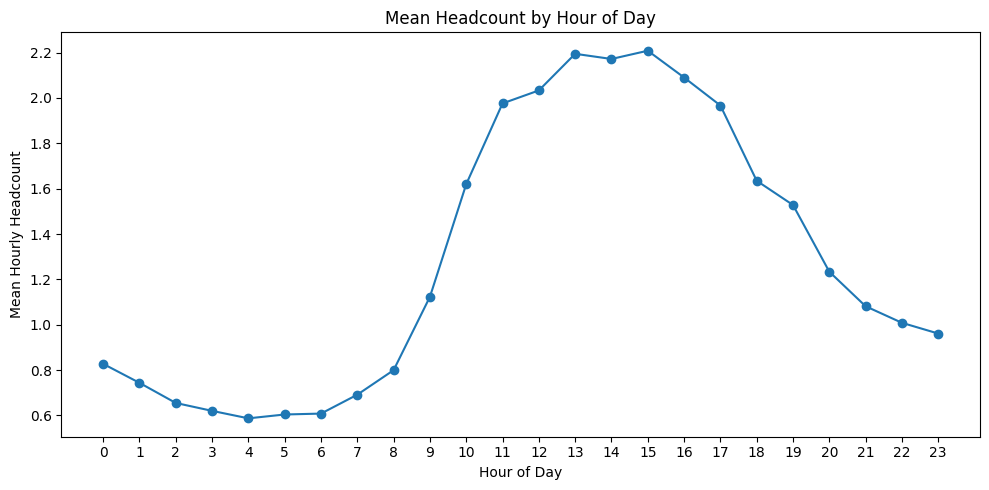

weekday_name
Monday       1.89
Tuesday      1.78
Wednesday    1.81
Thursday     1.87
Friday       1.60
Saturday     1.11
Sunday       1.37
Name: hourly_mean_headcount, dtype: float64

Hourly rows before lag filtering: 29,892
Model-ready rows: 29,052


,space,hour_start_local,hourly_mean_headcount,lag_1_hour,lag_24_hours,lag_168_hours
168,Space A,2023-12-07 19:00:00+11:00,0.913889,1.286111,0.196111,0.241111
169,Space A,2023-12-07 21:00:00+11:00,0.960000,0.913889,0.273889,0.764444
170,Space A,2023-12-08 10:00:00+11:00,0.429444,0.960000,0.386667,1.214444
171,Space A,2023-12-08 11:00:00+11:00,0.422222,0.429444,1.256667,1.415556
172,Space A,2023-12-08 12:00:00+11:00,0.603333,0.422222,0.817778,1.010000
173,Space A,2023-12-08 13:00:00+11:00,0.725000,0.603333,0.839444,1.023333
174,Space A,2023-12-08 14:00:00+11:00,0.853333,0.725000,0.855000,0.931111
175,Space A,2023-12-08 15:00:00+11:00,1.448889,0.853333,1.480000,0.696667
176,Space A,2023-12-08 16:00:00+11:00,1.252778,1.448889,0.919444,0.755556
177,Space A,2023-12-08 17:00:00+11:00,0.967778,1.252778,1.097778,0.877778


Overall training mean: 1.731


,model,mae,rmse,r2
0,Space and hour-of-week baseline,0.846,1.610,0.151
1,Overall mean baseline,1.034,1.762,-0.016


Training feature shape: (23859, 8)
Testing feature shape: (5193, 8)


,model,mae,rmse,r2
0,Decision tree,0.653,1.468,0.294
1,Linear regression,0.656,1.492,0.272
2,Space and hour-of-week baseline,0.846,1.610,0.151
3,Overall mean baseline,1.034,1.762,-0.016


,test_records,actual_mean_headcount,linear_mae,tree_mae
space,,,,
Space A,1391,0.999,0.377,0.398
Space B,1307,0.806,0.454,0.387
Space D,1384,1.524,0.476,0.456
Space E,1111,2.948,1.468,1.532


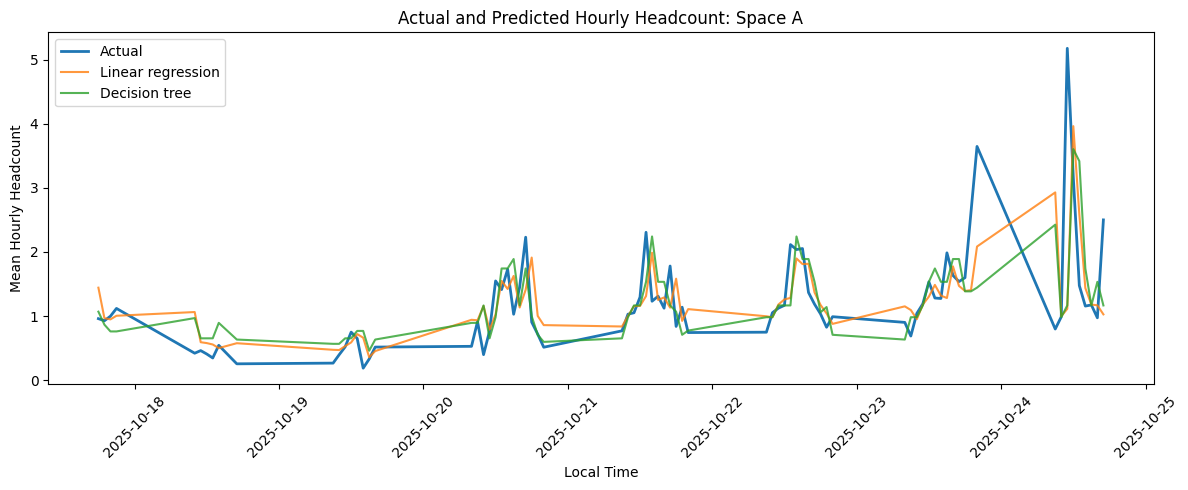

Saved model results to: C:\Users\sebkr\OneDrive - Monash University\Desktop\Github\MMA3001-Project\data\processed\forecasting_model_results.csv
Saved predictions to: C:\Users\sebkr\OneDrive - Monash University\Desktop\Github\MMA3001-Project\data\processed\hourly_headcount_predictions.csv


In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

current_folder = Path.cwd()

if current_folder.name == "notebooks":
    project_root = current_folder.parent
else:
    project_root = current_folder

processed_folder = project_root / "data" / "processed"


hourly_path = (
    processed_folder
    / "headcount_hourly_duration_weighted.csv"
)
hourly_data = pd.read_csv(
    hourly_path,
    low_memory=False,
)

print("Hourly dataset shape:", hourly_data.shape)
display(hourly_data.head())

print(hourly_data.columns.tolist())

hourly_data["interval_start_utc"] = pd.to_datetime(
    hourly_data["interval_start_utc"],
    errors="coerce",
    utc=True,
)

hourly_data["hour_start_local"] = (
    hourly_data["interval_start_utc"]
    .dt.tz_convert("Australia/Melbourne")
)

hourly_data = (
    hourly_data
    .dropna(
        subset=[
            "space",
            "interval_start_utc",
            "hourly_mean_headcount",
        ]
    )
    .sort_values(
        [
            "interval_start_utc",
            "space",
        ]
    )
    .reset_index(drop=True)
)

print("Usable hourly rows:", f"{len(hourly_data):,}")

print(
    "Observation period:",
    hourly_data["hour_start_local"].min(),
    "to",
    hourly_data["hour_start_local"].max(),
)

print(
    "Spaces:",
    sorted(hourly_data["space"].unique()),
)

display(
    hourly_data[
        [
            "space",
            "interval_start_utc",
            "hour_start_local",
            "hourly_mean_headcount",
            "observed_seconds",
            "valid_quarters",
        ]
    ].head(20)
) #Display the first 20 rows of the selected columns for a quick overview of the data.

# Create calendar features from Melbourne local time.

hourly_data["hour"] = (
    hourly_data["hour_start_local"]
    .dt.hour
)

hourly_data["day_of_week"] = (
    hourly_data["hour_start_local"]
    .dt.dayofweek
)

hourly_data["month"] = (
    hourly_data["hour_start_local"]
    .dt.month
)

hourly_data["is_weekend"] = (
    hourly_data["day_of_week"] >= 5
).astype(int)

hourly_data["hour_of_week"] = (
    hourly_data["day_of_week"] * 24
    + hourly_data["hour"]
)
display(
    hourly_data[
        [
            "space",
            "hour_start_local",
            "hour",
            "day_of_week",
            "month",
            "is_weekend",
            "hour_of_week",
            "hourly_mean_headcount",
        ]
    ].head(20)
)

print(
    "Hour range:",
    hourly_data["hour"].min(),
    "to",
    hourly_data["hour"].max(),
)

print(
    "Day-of-week range:",
    hourly_data["day_of_week"].min(),
    "to",
    hourly_data["day_of_week"].max(),
)

print(
    "Hour-of-week range:",
    hourly_data["hour_of_week"].min(),
    "to",
    hourly_data["hour_of_week"].max(),
) #Checking the ranges of the newly created features to ensure they are within expected bounds.

#Creating weekday names
weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday",
}

hourly_data["weekday_name"] = (
    hourly_data["day_of_week"]
    .map(weekday_names)
)

mean_by_hour = (
    hourly_data
    .groupby("hour")["hourly_mean_headcount"]
    .mean()
)

mean_by_hour.plot(
    marker="o",
    figsize=(10, 5),
    title="Mean Headcount by Hour of Day",
    xlabel="Hour of Day",
    ylabel="Mean Hourly Headcount",
)

plt.xticks(range(0, 24))
plt.tight_layout()
plt.show() #Plotting the mean headcount by hour of the day to visualize any patterns or trends in headcount throughout the day.

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

mean_by_weekday = (
    hourly_data
    .groupby("weekday_name")["hourly_mean_headcount"]
    .mean()
    .reindex(weekday_order)
)

display(
    mean_by_weekday
    .round(2)
)

hourly_data = (
    hourly_data
    .sort_values(
        ["space", "interval_start_utc"]
    )
    .reset_index(drop=True)
)

hourly_data["lag_1_hour"] = (
    hourly_data
    .groupby("space")["hourly_mean_headcount"]
    .shift(1)
)

hourly_data["lag_24_hours"] = (
    hourly_data
    .groupby("space")["hourly_mean_headcount"]
    .shift(24)
)

hourly_data["lag_168_hours"] = (
    hourly_data
    .groupby("space")["hourly_mean_headcount"]
    .shift(168)
) #Creating lag features for hour of the day, daay of the week and previous week to capture temporal dependencies in the headcount data.

model_data = (
    hourly_data
    .dropna(
        subset=[
            "lag_1_hour",
            "lag_24_hours",
            "lag_168_hours",
            "hourly_mean_headcount",
        ]
    )
    .copy()
)

print("Hourly rows before lag filtering:", f"{len(hourly_data):,}")
print("Model-ready rows:", f"{len(model_data):,}") #Removing rows with missing lag values to ensure the model has complete data for training and evaluation.

display(
    model_data[
        [
            "space",
            "hour_start_local",
            "hourly_mean_headcount",
            "lag_1_hour",
            "lag_24_hours",
            "lag_168_hours",
        ]
    ].head(20)
)

unique_timestamps = np.sort(
    model_data["interval_start_utc"]
    .unique()
)

split_position = int(
    len(unique_timestamps) * 0.80
)

split_timestamp = unique_timestamps[
    split_position
] #Using timestamps rather than reandomly selecting rows

train_data = model_data.loc[
    model_data["interval_start_utc"]
    < split_timestamp
].copy()

test_data = model_data.loc[
    model_data["interval_start_utc"]
    >= split_timestamp
].copy()

##Evaluation function
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

def evaluate_predictions(
    model_name,
    actual,
    predicted,
):
    """Calculate regression evaluation metrics."""
    return {
        "model": model_name,
        "mae": mean_absolute_error(
            actual,
            predicted,
        ),
        "rmse": mean_squared_error(
            actual,
            predicted,
        ) ** 0.5,
        "r2": r2_score(
            actual,
            predicted,
        ),
    }

results = []
target_column = "hourly_mean_headcount"

#Baseline model predicts same value for every test observation, which is the mean of the training target values.
overall_training_mean = (
    train_data[target_column]
    .mean()
)

overall_mean_predictions = np.full(
    shape=len(test_data),
    fill_value=overall_training_mean,
)

results.append(
    evaluate_predictions(
        model_name="Overall mean baseline",
        actual=test_data[target_column],
        predicted=overall_mean_predictions,
    )
)

print(
    "Overall training mean:",
    round(overall_training_mean, 3),
)

##baseline 2 predicts typical training headcount during each hour of the week
hour_of_week_means = (
    train_data
    .groupby(
        [
            "space",
            "hour_of_week",
        ]
    )[target_column]
    .mean()
    .rename("baseline_prediction")
    .reset_index()
)

test_with_baseline = test_data.merge(
    hour_of_week_means,
    on=[
        "space",
        "hour_of_week",
    ],
    how="left",
    validate="many_to_one",
) #Applying baseline to test data and evaluating performance

test_with_baseline[
    "baseline_prediction"
] = (
    test_with_baseline[
        "baseline_prediction"
    ]
    .fillna(overall_training_mean)
) #If a space-hour combination is not present in the training data, fill with overall mean

results.append(
    evaluate_predictions(
        model_name="Space and hour-of-week baseline",
        actual=test_with_baseline[target_column],
        predicted=test_with_baseline[
            "baseline_prediction"
        ],
    )
)

baseline_results = (
    pd.DataFrame(results)
    .sort_values("mae")
    .reset_index(drop=True)
)

display(
    baseline_results.round(3)
) #Displaying the baseline result 

numeric_features = [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "lag_1_hour",
    "lag_24_hours",
    "lag_168_hours",
]

categorical_features = [
    "space",
]

feature_columns = (
    numeric_features
    + categorical_features
)

target_column = "hourly_mean_headcount" #Using calendar features, lag features, and space as predictors for the target variable.

X_train = train_data[feature_columns]
y_train = train_data[target_column]

X_test = test_data[feature_columns]
y_test = test_data[target_column]

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape) #Creating training and testing datasets for model development and evaluation.

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features,
        ),
    ]
) #Numerical columns are filled with training medians if values are missing. The space labels are converted into numerical-indicator columns   

##linear regression model

linear_model = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor,
        ),
        (
            "model",
            LinearRegression(),
        ),
    ]
)

linear_model.fit(
    X_train,
    y_train,
)

linear_predictions = linear_model.predict(
    X_test
) #Making predictions on the test set using the trained linear regression model.

linear_predictions = np.clip(
    linear_predictions,
    0,
    None,
)#Ensuring accurate domain -> no negative headcount predictions

results.append(
    evaluate_predictions(
        model_name="Linear regression",
        actual=y_test,
        predicted=linear_predictions,
    )
)

tree_model = Pipeline(
    steps=[
        (
            "preprocessing",
            preprocessor,
        ),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=10,
                min_samples_leaf=20,
                random_state=42,
            ),
        ),
    ]
)

tree_model.fit(
    X_train,
    y_train,
) #Using a constrained tree to reduce risk of model overfitting 

tree_predictions = tree_model.predict(
    X_test
)

tree_predictions = np.clip(
    tree_predictions,
    0,
    None,
    
) #Ensuring accurate domain -> no negative headcount predictions

results.append(
    evaluate_predictions(
        model_name="Decision tree",
        actual=y_test,
        predicted=tree_predictions,
    )
)

#comparing all model results

results_table = (
    pd.DataFrame(results)
    .sort_values(
        "mae",
        ascending=True,
    )
    .reset_index(drop=True)
)

display(
    results_table.round(3)
)

#Creating an actual versus predicted plot

prediction_results = test_data[
    [
        "space",
        "interval_start_utc",
        "hour_start_local",
        target_column,
    ]
].copy()

prediction_results["linear_prediction"] = (
    linear_predictions
)

prediction_results["tree_prediction"] = (
    tree_predictions
)

prediction_results["linear_absolute_error"] = (
    prediction_results[target_column]
    - prediction_results["linear_prediction"]
).abs()

prediction_results["tree_absolute_error"] = (
    prediction_results[target_column]
    - prediction_results["tree_prediction"]
).abs() #calculating absolute errors for both models to assess prediction accuracy.

performance_by_space = (
    prediction_results
    .groupby("space")
    .agg(
        test_records=(
            target_column,
            "size",
        ),
        actual_mean_headcount=(
            target_column,
            "mean",
        ),
        linear_mae=(
            "linear_absolute_error",
            "mean",
        ),
        tree_mae=(
            "tree_absolute_error",
            "mean",
        ),
    )
    .round(3)
)

display(performance_by_space) #Summarizing model performance by space to identify any variations in prediction accuracy across different locations.

#Creating an actual vs predicted plot for the first 7 days  

example_space = (
    prediction_results["space"]
    .iloc[0]
)

example_start = (
    prediction_results.loc[
        prediction_results["space"]
        == example_space,
        "interval_start_utc",
    ]
    .min()
)

example_end = (
    example_start
    + pd.Timedelta(days=7)
)

example_data = prediction_results.loc[
    (
        prediction_results["space"]
        == example_space
    )
    & (
        prediction_results["interval_start_utc"]
        >= example_start
    )
    & (
        prediction_results["interval_start_utc"]
        < example_end
    )
].copy()

#Plot
plt.figure(figsize=(12, 5))

plt.plot(
    example_data["hour_start_local"],
    example_data[target_column],
    label="Actual",
    linewidth=2,
)

plt.plot(
    example_data["hour_start_local"],
    example_data["linear_prediction"],
    label="Linear regression",
    alpha=0.8,
)

plt.plot(
    example_data["hour_start_local"],
    example_data["tree_prediction"],
    label="Decision tree",
    alpha=0.8,
)

plt.title(
    f"Actual and Predicted Hourly Headcount: "
    f"{example_space}"
)

plt.xlabel("Local Time")
plt.ylabel("Mean Hourly Headcount")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

model_results_path = (
    processed_folder
    / "forecasting_model_results.csv"
)

predictions_path = (
    processed_folder
    / "hourly_headcount_predictions.csv"
)

results_table.to_csv(
    model_results_path,
    index=False,
)

prediction_results.to_csv(
    predictions_path,
    index=False,
)

print(
    "Saved model results to:",
    model_results_path.resolve(),
)

print(
    "Saved predictions to:",
    predictions_path.resolve(),
) #Saving results


Results Summary

Four forecasting approaches were evaluated (3 were graphed as mean baseline was excluded). A chronological train-test split was used: An overall mean baseline, a space/hour of the week baseline, linear regression and decision tree regression. The best performing model according to mean absolute error was the decision tree model, with an MAE of 0.653, an RMSE vaue of 1.468 and an R^2 value of 0.294-> meaning that only ~29.4% of the model could explain the data. 

The space/hour baseline achieved an MAE value of 0.846, showing that recurring weekly schedules contained information about workshop occupancy - however it wasn't a complete reliable indicator.

Hourly headcount followed a clear time-of-day pattern, with lower occupancy outside normal campus operating hours and higher occupancy during the daytime.

Headcount also varied across the week, with Monday and Thursday rated highest for occupancy with Friday and Weekends ranking the lowest. These patterns support the use of hour, day of week and hour of week as forecasting variables.


The decision tree captured non-linear relationships between occupancy, time of day and weekly patterns - however it struggled with large spikes in occupancy as seen in model space A for the 24/25th of October. The actual v predicted plot indicates that the decision tree captured the overall pattern but tended to underestimated peaks and lags 

Conclusion

This project developed a reproducible workflow for forecasting hourly mean headcount across a campus workshop space. Irregular high-frequency occupancy observations were converted into a regular time series using duration-weighted numerical aggregation. Comparing this method with an unweighted mean demonstrated results that were closer to the actual data.

The forecasting comparison showed that a decision tree was the best model, producing the lowest Mean Weighted Average (MAE) and the highest R^2 Value. 

The models were most effective at representing regular occupancy patterns and less effective at predicting sudden high-headcount periods. The results demonstrate that useful short-term occupancy forecasts can be obtained from calendar patterns and recent occupancy history, although improved space metadata, timetables and reliable environmental sensor mappings would likely strengthen future models.

In [20]:
##Compact final results table

report_results = results_table.copy()

report_results = report_results.rename(
    columns={
        "model": "Model",
        "mae": "MAE",
        "rmse": "RMSE",
        "r2": "R²",
    }
)

report_results[
    ["MAE", "RMSE", "R²"]
] = report_results[
    ["MAE", "RMSE", "R²"]
].round(3)

display(report_results)

,Model,MAE,RMSE,R²
0,Decision tree,0.653,1.468,0.294
1,Linear regression,0.656,1.492,0.272
2,Space and hour-of-week baseline,0.846,1.610,0.151
3,Overall mean baseline,1.034,1.762,-0.016
